# Comparación de algoritmos
Versión documentada el 26/10/2026: corpus simulado de 300 correos.
La selección y el diagnóstico usan 280/20; las versiones finales se ajustan con 10/100/200/300.
Los 25 de data/test no se usan en este notebook. La evaluación diagnóstica no demuestra generalización independiente de los modelos finales.


In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import pandas as pd
import matplotlib.pyplot as plt
from src.utils import load_config, project_path
from src.data_processing import load_data, split_data
config = load_config()
data = load_data(project_path(config["data_path"]))
train, test = split_data(data, config["test_size"], config["seed"], config["cv_folds"], holdout_manifest=project_path(config["holdout_manifest"]) if config.get("holdout_manifest") else None)


In [2]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from src.model import build_pipeline
cv = StratifiedKFold(config["cv_folds"], shuffle=True, random_state=config["seed"])
rows = []
for kind in ["baseline", "logistic", "svm"]:
    scores = cross_validate(build_pipeline(kind), train.texto, train.clasificacion, cv=cv, scoring="f1_macro", return_train_score=True)
    rows.append({"modelo": kind, "F1_CV": scores["test_score"].mean(), "F1_train": scores["train_score"].mean()})
display(pd.DataFrame(rows))

,modelo,F1_CV,F1_train
0,baseline,0.112179,0.112187
1,logistic,0.937289,1.000000
2,svm,0.961725,1.000000


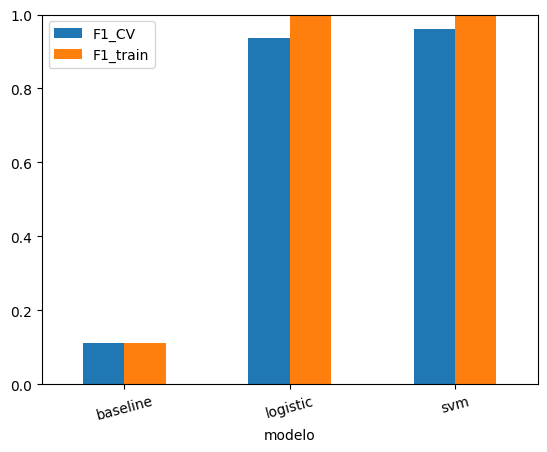

In [3]:
pd.DataFrame(rows).set_index("modelo")[["F1_CV", "F1_train"]].plot.bar(rot=15, ylim=(0, 1))
plt.show()